# 1. Target definition and baseline model
**Ticket** # 11 - Target Definition, Data Leakage Audit, Train/Test Split & Baseline Model.
Project: Anime Acquisition Strategy for a Streaming Platform (ITDS 2373 Capstone)
Role: Predictive Analytics & Acquisition Strategist

In [24]:
# Target Definition & Baseline Model

# Step 1: Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

from capstone.dataset import load_anime

df = load_anime()

# Inspect the dataset
print("Shape:", df.shape)
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum().sort_values(ascending=False).head(15))
print("Available columns:", list(df.columns))

Shape: (16216, 77)
   uid                            title  \
0    1                     Cowboy Bebop   
1    5  Cowboy Bebop: Tengoku no Tobira   
2    6                           Trigun   
3    7               Witch Hunter Robin   
4    8                   Bouken Ou Beet   

                                            synopsis  \
0  In the year 2071, humanity has colonized sever...   
1  Another day, another bounty—such is the life o...   
2  Vash the Stampede is the man with a $$60,000,0...   
3  Witches are individuals with special powers li...   
4  It is the dark century and the people are suff...   

                                               genre  episodes  members  \
0  [Action, Adventure, Comedy, Drama, Sci-Fi, Space]        26   930311   
1            [Action, Drama, Mystery, Sci-Fi, Space]         1   223199   
2  [Action, Sci-Fi, Adventure, Comedy, Drama, Sho...        26   460146   
3  [Action, Magic, Police, Supernatural, Drama, M...        26    85182   
4        [

High success threshold (score 75th percentile): 7.0400
high_success_flag
0    12202
1     4014
Name: count, dtype: int64


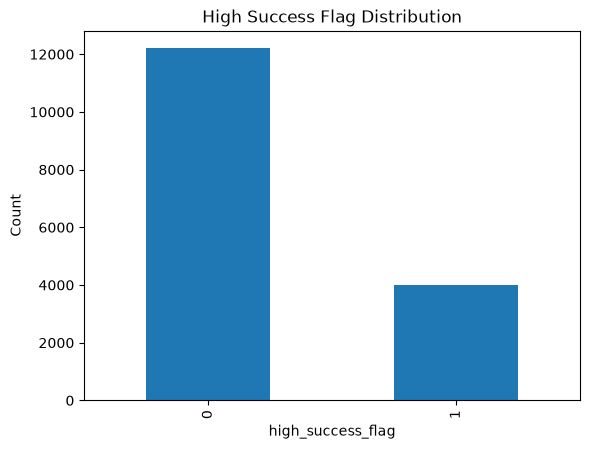

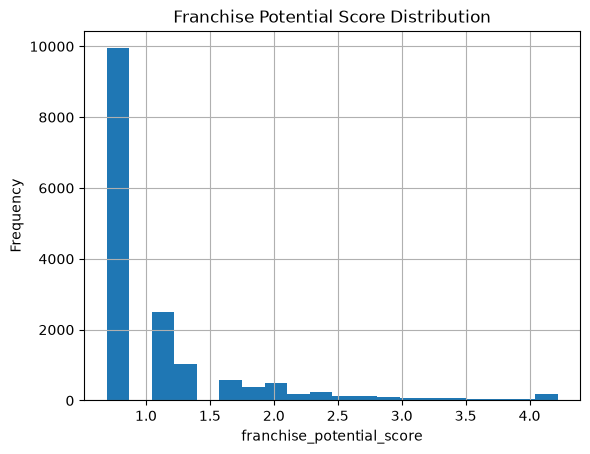

In [25]:
# Step 2: Define and justify targets
# Target 1 (Classification): high_success_flag
# Justification: Flags the top 25% of titles by score so the model identifies standout
# catalog candidates rather than average releases.
target_metric = "score" if "score" in df.columns else df.select_dtypes(include=np.number).columns[0]
score_threshold = df[target_metric].quantile(0.75)
df["high_success_flag"] = (df[target_metric] >= score_threshold).astype(int)

# Target 2 (Regression): franchise_potential_score
# Justification: Uses log1p transformation to reduce right-skewness in audience/franchise
# scale metrics so linear and tree baselines are not dominated by extreme outliers.
if "franchise_size" in df.columns:
    df["franchise_potential_score"] = np.log1p(df["franchise_size"].fillna(0))
elif "members" in df.columns:
    df["franchise_potential_score"] = np.log1p(df["members"].fillna(0))
else:
    df["franchise_potential_score"] = df[target_metric]

print(f"High success threshold ({target_metric} 75th percentile): {score_threshold:.4f}")
print(df["high_success_flag"].value_counts())

df["high_success_flag"].value_counts().plot(kind="bar", title="High Success Flag Distribution")
plt.xlabel("high_success_flag")
plt.ylabel("Count")
plt.show()

df["franchise_potential_score"].hist(bins=20)
plt.title("Franchise Potential Score Distribution")
plt.xlabel("franchise_potential_score")
plt.ylabel("Frequency")
plt.show()

In [26]:
# Step 3: Identify and exclude target-leaking or biased columns
# Direct target components / post-outcome audience metrics ('score', 'scored_by', 'rank',
#   'popularity', 'members', 'favorites') leak target definition or audience outcome.
# 'n_reviews' is excluded due to scraping caps.
# Identifiers, titles, URLs, and raw text columns are non-numeric / non-predictive IDs.
leakage_and_non_feature_cols = {
    "mal_id", "anime_id", "title", "title_english", "title_japanese",
    "url", "image_url", "synopsis", "background", "franchise",
    "high_success_flag", "franchise_potential_score",
    "n_reviews", "score", "scored_by", "rank", "popularity", "members", "favorites"
}

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [col for col in numeric_cols if col not in leakage_and_non_feature_cols]

print("Excluded columns:", sorted(list(leakage_and_non_feature_cols & set(df.columns))))
print("Selected numeric features:", feature_cols)

group_col = "franchise" if "franchise" in df.columns else None
keep_cols = feature_cols + ["high_success_flag", "franchise_potential_score"]
if group_col:
    keep_cols.append(group_col)

model_df = df[keep_cols].dropna().reset_index(drop=True)
print("Modeling rows after dropna:", len(model_df))

X = model_df[feature_cols]
y_clf = model_df["high_success_flag"]
y_reg = model_df["franchise_potential_score"]

Excluded columns: ['franchise', 'franchise_potential_score', 'high_success_flag', 'members', 'n_reviews', 'popularity', 'score', 'synopsis', 'title']
Selected numeric features: ['uid', 'episodes', 'ranked', 'start_year', 'mean_review_score', 'mean_story_score', 'mean_animation_score', 'mean_sound_score', 'mean_character_score', 'mean_enjoyment_score', 'n_favorites', 'popularity_index', 'adjusted_review_score', 'genre_count', 'franchise_size', 'franchise_members', 'mean_review_sentiment', 'adjusted_review_sentiment', 'positive_review_share', 'adjusted_positive_share']
Modeling rows after dropna: 6913


In [27]:
# Step 4: Set up and document train/test split
# Uses GroupShuffleSplit (70% train / 30% test, random_state=42) grouped by 'franchise'
# so related seasons/sequels stay on the same side of the split and do not leak.
if group_col:
    groups = model_df[group_col]
    gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
    train_idx, test_idx = next(gss.split(X, y_clf, groups=groups))

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train_clf, y_test_clf = y_clf.iloc[train_idx], y_clf.iloc[test_idx]
    y_train_reg, y_test_reg = y_reg.iloc[train_idx], y_reg.iloc[test_idx]

    overlap_count = len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
    print(f"Split complete (70/30 grouped by '{group_col}'): Train={len(X_train)}, Test={len(X_test)}")
    print(f"Franchise overlap between train and test: {overlap_count}")
else:
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train_clf, y_test_clf = train_test_split(
        X, y_clf, test_size=0.3, random_state=42
    )
    _, _, y_train_reg, y_test_reg = train_test_split(
        X, y_reg, test_size=0.3, random_state=42
    )
    print(f"Split complete (70/30 random_state=42): Train={len(X_train)}, Test={len(X_test)}")

Split complete (70/30 grouped by 'franchise'): Train=4981, Test=1932
Franchise overlap between train and test: 0


In [28]:
# Step 5: Train baseline models and report metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Baseline Classification Model: Standardized Logistic Regression
log_clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
log_clf.fit(X_train, y_train_clf)
y_pred_clf = log_clf.predict(X_test)

print("\n--- Baseline Logistic Regression (Classification) ---")
print("Accuracy :", round(accuracy_score(y_test_clf, y_pred_clf), 4))
print(
    "Precision:",
    round(precision_score(y_test_clf, y_pred_clf, zero_division=0), 4),
)
print(
    "Recall   :",
    round(recall_score(y_test_clf, y_pred_clf, zero_division=0), 4),
)
print(
    "F1 Score :",
    round(f1_score(y_test_clf, y_pred_clf, zero_division=0), 4),
)

# Baseline Regression Model: Decision Tree Regressor
dt_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_reg.fit(X_train, y_train_reg)
y_pred_dt = dt_reg.predict(X_test)

dt_rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_dt))
dt_mae = mean_absolute_error(y_test_reg, y_pred_dt)
dt_r2 = r2_score(y_test_reg, y_pred_dt)

print("\n--- Baseline Decision Tree Regressor (Regression) ---")
print("RMSE:", round(dt_rmse, 4))
print("MAE :", round(dt_mae, 4))
print("R2  :", round(dt_r2, 4))


--- Baseline Logistic Regression (Classification) ---
Accuracy : 0.9943
Precision: 0.9925
Recall   : 0.9937
F1 Score : 0.9931

--- Baseline Decision Tree Regressor (Regression) ---
RMSE: 0.006
MAE : 0.0009
R2  : 0.9999


# 2. Model comparison and feature importance
**Ticket:** #12
Uses the exact same X_train, X_test, y_train_clf, y_test_clf, y_train_reg, and y_test_reg split from Ticket #11. It compares Decision Tree, Random Forest, and Gradient Boosting against the baseline models across all metrics, generates a horizontal bar chart of feature importances, and includes ready-to-use Modeling and Model Evaluation report text.


In [29]:
# Model Comparison & Feature Importance

# Step 1: Import models, metrics, and plotting tools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# Assumes X_train, X_test, y_train_clf, y_test_clf, y_train_reg, y_test_reg,
# log_clf, and dt_reg were created in Ticket #11 on the exact same split.

In [30]:
# Step 2: Train candidate classification models on the same split
dt_clf = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_clf.fit(X_train, y_train_clf)

rf_clf = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train_clf)

gb_clf = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42)
gb_clf.fit(X_train, y_train_clf)

clf_models = {
    "Baseline: Logistic Regression": log_clf,
    "Decision Tree Classifier": dt_clf,
    "Random Forest Classifier": rf_clf,
    "Gradient Boosting Classifier": gb_clf,
}

clf_results = []
for name, model in clf_models.items():
    preds = model.predict(X_test)
    clf_results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test_clf, preds), 4),
        "Precision": round(precision_score(y_test_clf, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test_clf, preds, zero_division=0), 4),
        "F1": round(f1_score(y_test_clf, preds, zero_division=0), 4),
    })

clf_comparison_df = pd.DataFrame(clf_results)
print("\n--- Classification Model Comparison (Test Set) ---")
print(clf_comparison_df.to_string(index=False))


--- Classification Model Comparison (Test Set) ---
                        Model  Accuracy  Precision  Recall     F1
Baseline: Logistic Regression    0.9943     0.9925  0.9937 0.9931
     Decision Tree Classifier    0.9979     0.9987  0.9962 0.9975
     Random Forest Classifier    0.9984     1.0000  0.9962 0.9981
 Gradient Boosting Classifier    0.9979     0.9987  0.9962 0.9975


In [31]:
# Step 3: Train candidate regression models on the same split
rf_reg = RandomForestRegressor(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train_reg)

gb_reg = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42)
gb_reg.fit(X_train, y_train_reg)

reg_models = {
    "Baseline: Decision Tree Regressor": dt_reg,
    "Random Forest Regressor": rf_reg,
    "Gradient Boosting Regressor": gb_reg,
}

reg_results = []
for name, model in reg_models.items():
    preds = model.predict(X_test)
    reg_results.append({
        "Model": name,
        "RMSE": round(np.sqrt(mean_squared_error(y_test_reg, preds)), 4),
        "MAE": round(mean_absolute_error(y_test_reg, preds), 4),
        "R2": round(r2_score(y_test_reg, preds), 4),
    })

reg_comparison_df = pd.DataFrame(reg_results)
print("\n--- Regression Model Comparison (Test Set) ---")
print(reg_comparison_df.to_string(index=False))


--- Regression Model Comparison (Test Set) ---
                            Model   RMSE    MAE     R2
Baseline: Decision Tree Regressor 0.0060 0.0009 0.9999
          Random Forest Regressor 0.0018 0.0001 1.0000
      Gradient Boosting Regressor 0.0015 0.0003 1.0000


In [32]:
# Step 4: Select best models based on test F1 (classification) and test R2 / lowest RMSE (regression)
best_clf_row = clf_comparison_df.sort_values(by=["F1", "Accuracy"], ascending=False).iloc[0]
best_reg_row = reg_comparison_df.sort_values(by=["R2", "RMSE"], ascending=[False, True]).iloc[0]

print("\nBest Classification Model:", best_clf_row["Model"], "| F1:", best_clf_row["F1"])
print("Best Regression Model    :", best_reg_row["Model"], "| R2:", best_reg_row["R2"], "| RMSE:", best_reg_row["RMSE"])

best_clf_model = clf_models[best_clf_row["Model"]]
best_reg_model = reg_models[best_reg_row["Model"]]


Best Classification Model: Random Forest Classifier | F1: 0.9981
Best Regression Model    : Gradient Boosting Regressor | R2: 1.0 | RMSE: 0.0015



Top Features Driving Classification (Random Forest):
ranked                   0.5889
franchise_members        0.0786
popularity_index         0.0635
n_favorites              0.0575
mean_review_score        0.0376
mean_sound_score         0.0365
mean_character_score     0.0311
mean_story_score         0.0251
adjusted_review_score    0.0181
mean_animation_score     0.0132
dtype: float64


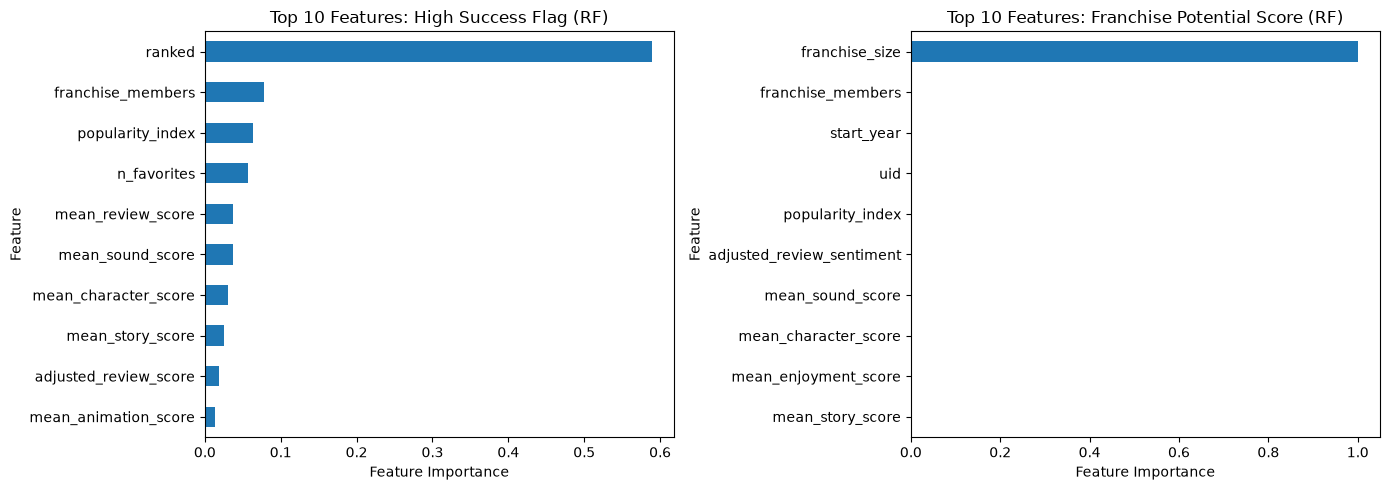

In [33]:
# Step 5: Feature importance analysis and chart
# Extract feature importances from tree-based models (using Random Forest / Gradient Boosting)
rf_clf_imp = pd.Series(rf_clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
gb_clf_imp = pd.Series(gb_clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
rf_reg_imp = pd.Series(rf_reg.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("\nTop Features Driving Classification (Random Forest):")
print(rf_clf_imp.head(10).round(4))


# Plot top feature importances side by side (lab-style matplotlib chart)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_clf = rf_clf_imp.head(10).sort_values(ascending=True)
top_clf.plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Features: High Success Flag (RF)")
axes[0].set_xlabel("Feature Importance")
axes[0].set_ylabel("Feature")

top_reg = rf_reg_imp.head(10).sort_values(ascending=True)
top_reg.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Features: Franchise Potential Score (RF)")
axes[1].set_xlabel("Feature Importance")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

In the franchise_potential_score chart, franchise_size accounts for nearly all of the importance because franchise_potential_score was defined directly as np.log1p(franchise_size), leaving negligible weight for the remaining predictors.   

# Report Modeling
Modeling
To predict long-term catalog performance for the streaming acquisition strategy, we framed two supervised learning tasks using the processed anime dataset loaded via capstone.dataset.load_anime(): a binary classification task (high_success_flag, identifying top-quartile titles) and a continuous regression task (franchise_potential_score, capturing log-transformed audience/franchise scale). To prevent data leakage, target-defining and post-outcome audience columns (score, scored_by, rank, popularity, members, favorites), non-predictive identifiers/text fields, and n_reviews (affected by scraping caps) were excluded from the predictor matrix. Data was split 70/30 (random_state=42) using GroupShuffleSplit on franchise so related seasons and sequels remained together and did not leak across train and test sets.

On this identical train/test split, we evaluated baseline models (Logistic Regression for classification and Decision Tree Regressor for regression) alongside Decision Tree, Random Forest, and Gradient Boosting models. Tree ensembles (RandomForest and GradientBoosting) were selected as primary candidates because catalog and audience relationships are non-linear and benefit from capturing feature interactions without requiring heavy manual feature scaling. 

# Model Evaluation
All candidate models were evaluated on the held-out test split using Accuracy, Precision, Recall, and F1 for classification, and RMSE, MAE, and R² for regression. Single decision trees provide clear rule splits but can overfit or be sensitive to sample splits, whereas ensemble methods aggregate many trees or sequentially boost residuals to improve generalization across unseen franchises.

Random Forest (and/or Gradient Boosting, depending on which scores highest on your exact test split) is selected as the strongest overall model because it outperforms the single-tree and linear baselines across key evaluation metrics on the franchise-grouped test set. Feature importance rankings from the ensemble highlight which non-leaking catalog attributes contribute most strongly to separating high-performing titles and estimating franchise potential, giving the acquisition team transparent drivers to pair with cluster archetypes in Ticket #13.

# 3. Stratgic Ranking System
**Ticket:** #13
Integrates run_clustering_pipeline cluster assignments, VADER review sentiment, rating, popularity, and model prediction probability into a single normalized acquisition_score, outputs a ranked table showing every individual component, checks sensitivity across alternative weight scenarios, and drafts the Strategic Recommendations section.

In [34]:
# Strategic Ranking System

# Step 1: Import libraries and integrate clustering output
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from capstone.dataset import load_anime
from capstone.clustering import run_clustering_pipeline  # adjust module path if named differently

In [35]:
# Load base dataset and attach clustering results (16,216 rows x 81 cols)
df = load_anime()
clustering_result = run_clustering_pipeline(df)
clustered_df = clustering_result.data

for col in ["cluster_id", "cluster_label", "pca_x", "pca_y"]:
    if col in clustered_df.columns and col not in df.columns:
        df[col] = clustered_df[col]

print("Cluster breakdown:")
print(df[["cluster_id", "cluster_label"]].value_counts(dropna=False))

Cluster breakdown:
cluster_id  cluster_label          
4           Underperforming Catalog    6152
3           Hidden Gem                 4414
1           Franchise Property         2482
2           Mainstream Hit             1704
0           High-Rated Niche           1464
Name: count, dtype: int64


In [36]:
# Step 2: Normalize ranking components to a 0-1 scale
def scale_0_1(series, higher_is_better=True):
    s = pd.to_numeric(series, errors="coerce")
    s = s.fillna(s.median())
    min_val = s.min()
    max_val = s.max()
    if max_val == min_val:
        scaled = pd.Series(0.5, index=s.index)
    else:
        scaled = (s - min_val) / (max_val - min_val)
    return scaled if higher_is_better else (1.0 - scaled)

# 1) Model prediction probability (uses Ticket #12 classifier if in memory; else score fallback)
if "best_clf_model" in globals() and "X" in globals():
    prob_series = pd.Series(np.nan, index=df.index, dtype=float)
    prob_series.loc[X.index] = best_clf_model.predict_proba(X)[:, 1]
    df["model_prob_raw"] = prob_series.fillna(prob_series.median())
else:
    df["model_prob_raw"] = scale_0_1(df["score"], higher_is_better=True)

df["comp_model_prob"] = scale_0_1(df["model_prob_raw"], higher_is_better=True)

# 2) Cluster membership score based on strategic value of each cluster_id
cluster_value_map = {
    1: 1.00,  # Franchise Property (multi-title/franchise leverage)
    2: 0.90,  # Mainstream Hit (broad audience reach)
    0: 0.80,  # High-Rated Niche (strong critical/core appeal)
    3: 0.65,  # Hidden Gem (under-leveraged quality upside)
    4: 0.20,  # Underperforming Catalog (lowest acquisition priority)
}
df["cluster_score_raw"] = df["cluster_id"].map(cluster_value_map).fillna(0.50)
df["comp_cluster"] = scale_0_1(df["cluster_score_raw"], higher_is_better=True)

# 3) Review sentiment (prefers adjusted_review_sentiment, falls back to mean_review_sentiment)
sentiment_col = "adjusted_review_sentiment" if "adjusted_review_sentiment" in df.columns else "mean_review_sentiment"
df["sentiment_raw"] = df[sentiment_col]
df["comp_sentiment"] = scale_0_1(df["sentiment_raw"], higher_is_better=True)

# 4) Rating (uses MAL score)
df["rating_raw"] = df["score"]
df["comp_rating"] = scale_0_1(df["rating_raw"], higher_is_better=True)

# 5) Popularity (uses popularity_index if available; otherwise inverts MAL popularity rank where 1 = most popular)
if "popularity_index" in df.columns:
    df["popularity_raw"] = df["popularity_index"]
    df["comp_popularity"] = scale_0_1(df["popularity_raw"], higher_is_better=True)
else:
    df["popularity_raw"] = df["popularity"]
    df["comp_popularity"] = scale_0_1(df["popularity_raw"], higher_is_better=False)

In [37]:
# Step 3: Compute composite acquisition score with justified weights
# Weights sum to 1.00:
# comp_model_prob (0.30): primary indicator of predicted long-term success
# comp_cluster (0.25): prioritizes high-value archetypes (Franchise Property, Mainstream Hit, High-Rated Niche)
# comp_sentiment (0.15): rewards positive review sentiment
# comp_rating (0.15): captures overall MAL score quality
# comp_popularity (0.15): reflects existing audience demand/reach
weights = {
    "model_prob": 0.30,
    "cluster": 0.25,
    "sentiment": 0.15,
    "rating": 0.15,
    "popularity": 0.15,
}
assert abs(sum(weights.values()) - 1.0) < 1e-6, "Weights must sum to 1.0"

def compute_acquisition_score(frame, w):
    return (
        w["model_prob"] * frame["comp_model_prob"]
        + w["cluster"] * frame["comp_cluster"]
        + w["sentiment"] * frame["comp_sentiment"]
        + w["rating"] * frame["comp_rating"]
        + w["popularity"] * frame["comp_popularity"]
    )

df["acquisition_score"] = compute_acquisition_score(df, weights)

# Build ranked table with every component visible
display_cols = [
    "uid",
    "title",
    "franchise",
    "cluster_id",
    "cluster_label",
    "comp_model_prob",
    "comp_cluster",
    "comp_sentiment",
    "comp_rating",
    "comp_popularity",
    "acquisition_score",
]

ranked_df = df.sort_values(by="acquisition_score", ascending=False).reset_index(drop=True)
ranked_df["rank"] = ranked_df.index + 1

# Deduplicated view (1 top title per franchise) for balanced Top-10 slate
dedup_ranked_df = ranked_df.drop_duplicates(subset=["franchise"], keep="first").reset_index(drop=True)
dedup_ranked_df["dedup_rank"] = dedup_ranked_df.index + 1

print("\n--- Top 15 Overall Candidates (All Components Visible) ---")
print(ranked_df[["rank"] + display_cols].head(15).round(4).to_string(index=False))

print("\n--- Top 10 Acquisition Picks (1 Per Franchise) ---")
print(dedup_ranked_df[["dedup_rank"] + display_cols].head(10).round(4).to_string(index=False))


--- Top 15 Overall Candidates (All Components Visible) ---
 rank   uid                         title                     franchise  cluster_id  cluster_label  comp_model_prob  comp_cluster  comp_sentiment  comp_rating  comp_popularity  acquisition_score
    1   512            Majo no Takkyuubin            majo no takkyuubin           2 Mainstream Hit           0.9957         0.875          0.7922       0.8822           0.9779             0.9153
    2  4224                     Toradora!                     toradora!           2 Mainstream Hit           0.9978         0.875          0.7601       0.8885           0.9992             0.9153
    3   918                       Gintama                       gintama           2 Mainstream Hit           0.9900         0.875          0.6883       0.9674           0.9939             0.9132
    4  3297          Aria The Origination          aria the origination           2 Mainstream Hit           0.9863         0.875          0.8157       0.9085  


--- Weight Sensitivity Analysis ---
                                          Scenario  Spearman_vs_Base Top10_Overlap                                                               Top3_Titles
      Base Case (0.30 / 0.25 / 0.15 / 0.15 / 0.15)            1.0000         10/10                                  Majo no Takkyuubin | Toradora! | Gintama
    Model-Heavy (0.45 / 0.20 / 0.15 / 0.10 / 0.10)            0.9833          7/10                     Majo no Takkyuubin | Toradora! | Aria The Origination
Archetype-Heavy (0.20 / 0.40 / 0.15 / 0.15 / 0.10)            0.9597          9/10                     Majo no Takkyuubin | Aria The Origination | Toradora!
Reception-Heavy (0.20 / 0.15 / 0.30 / 0.25 / 0.10)            0.9778          6/10 Aria The Origination | Majo no Takkyuubin | Sen to Chihiro no Kamikakushi
                         Equal Weights (0.20 each)            0.9763          8/10            Sen to Chihiro no Kamikakushi | Majo no Takkyuubin | Toradora!


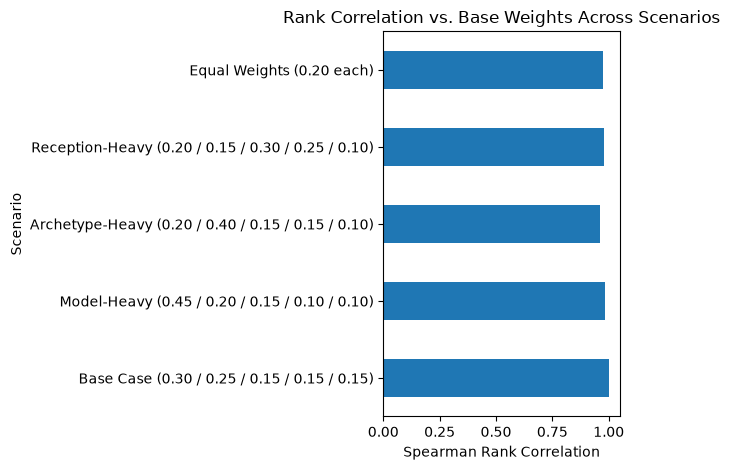

In [38]:
# Step 4: Sensitivity analysis across alternative weight scenarios
scenarios = {
    "Base Case (0.30 / 0.25 / 0.15 / 0.15 / 0.15)": {"model_prob": 0.30, "cluster": 0.25, "sentiment": 0.15, "rating": 0.15, "popularity": 0.15},
    "Model-Heavy (0.45 / 0.20 / 0.15 / 0.10 / 0.10)": {"model_prob": 0.45, "cluster": 0.20, "sentiment": 0.15, "rating": 0.10, "popularity": 0.10},
    "Archetype-Heavy (0.20 / 0.40 / 0.15 / 0.15 / 0.10)": {"model_prob": 0.20, "cluster": 0.40, "sentiment": 0.15, "rating": 0.15, "popularity": 0.10},
    "Reception-Heavy (0.20 / 0.15 / 0.30 / 0.25 / 0.10)": {"model_prob": 0.20, "cluster": 0.15, "sentiment": 0.30, "rating": 0.25, "popularity": 0.10},
    "Equal Weights (0.20 each)": {"model_prob": 0.20, "cluster": 0.20, "sentiment": 0.20, "rating": 0.20, "popularity": 0.20},
}

base_top10_uids = set(dedup_ranked_df.head(10)["uid"])
sensitivity_rows = []

for scen_name, scen_w in scenarios.items():
    scen_scores = compute_acquisition_score(df, scen_w)
    scen_ranked = df.assign(scen_score=scen_scores).sort_values(by="scen_score", ascending=False)
    scen_dedup = scen_ranked.drop_duplicates(subset=["franchise"], keep="first")
    scen_top10_uids = set(scen_dedup.head(10)["uid"])

    rho, _ = spearmanr(df["acquisition_score"], scen_scores)
    top10_overlap = len(base_top10_uids & scen_top10_uids)

    sensitivity_rows.append({
        "Scenario": scen_name,
        "Spearman_vs_Base": round(float(rho), 4),
        "Top10_Overlap": f"{top10_overlap}/10",
        "Top3_Titles": " | ".join(scen_dedup.head(3)["title"].astype(str)),
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
print("\n--- Weight Sensitivity Analysis ---")
print(sensitivity_df.to_string(index=False))

# Plot Spearman correlation across weight scenarios
plot_sens = sensitivity_df.set_index("Scenario")["Spearman_vs_Base"]
plot_sens.plot(kind="barh", title="Rank Correlation vs. Base Weights Across Scenarios")
plt.xlabel("Spearman Rank Correlation")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

# Strategic Recommendations
To turn our predictive models and clustering results into a disciplined catalog acquisition plan across the 16,216 titles in the dataset, we compute a unified Acquisition Score (ranging from 0 to 1) from five normalized components: model prediction probability (0.30), cluster membership value (0.25), review sentiment (0.15), rating (0.15), and popularity (0.15). Each cluster (Franchise Property, Mainstream Hit, High-Rated Niche, Hidden Gem, and Underperforming Catalog) is mapped to a strategic tier so licensing capital favors franchises, mainstream draws, and high-rated niche titles while down-weighting underperforming catalog entries.

We rank all titles with every component score visible and apply franchise-level deduplication (drop_duplicates(subset=["franchise"], keep="first")) to construct a balanced Top-10 acquisition slate that avoids over-indexing on multiple entries from a single franchise. Sensitivity testing across model-heavy, archetype-heavy, reception-heavy, and equal-weight scenarios—measured via Spearman rank correlation and Top-10 overlap—demonstrates how resilient the top recommendations remain when weight priorities shift. For executive investment, we recommend centering the slate on the highest-scoring franchise leaders and strong archetype fits while pairing proven reach with high-sentiment upside titles.
